# Hospital Appointment Insight: Round 1 — Data Understanding, Preprocessing & EDA
**Organization:** CareBridge Hospitals  
**Domain:** Healthcare Analytics  
**Challenge ID:** U23AD491 | **Candidate:** Manojkumar S (Register No: U23AD491)  
**Business Objective:** Understand attendance drivers, reduce missed visits, and improve clinic scheduling.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
print('Libraries successfully loaded.')

Libraries successfully loaded.


## 1. Data Understanding & Quality Audit
We inspect all five relational raw CSV files (`appointments.csv`, `patients.csv`, `doctors.csv`, `reminders.csv`, `calendar.csv`).

In [2]:
raw_dir = 'data/raw' if os.path.exists('data/raw') else '../data/raw'
df_appointments = pd.read_csv(os.path.join(raw_dir, 'appointments.csv'))
df_patients = pd.read_csv(os.path.join(raw_dir, 'patients.csv'))
df_doctors = pd.read_csv(os.path.join(raw_dir, 'doctors.csv'))
df_reminders = pd.read_csv(os.path.join(raw_dir, 'reminders.csv'))
df_calendar = pd.read_csv(os.path.join(raw_dir, 'calendar.csv'))

print(f'Appointments shape: {df_appointments.shape}')
print(f'Patients shape:     {df_patients.shape}')
print(f'Doctors shape:      {df_doctors.shape}')
print(f'Reminders shape:    {df_reminders.shape}')
print(f'Calendar shape:     {df_calendar.shape}')

Appointments shape: (5012, 9)
Patients shape:     (1500, 6)
Doctors shape:      (30, 5)
Reminders shape:    (4278, 5)
Calendar shape:     (366, 5)


In [3]:
df_appointments.head()

,appointment_id,patient_id,doctor_id,appointment_date,booking_date,department,appointment_status,waiting_days,appointment_time
0,APP-13235,PAT-1539,DOC-102,2024-12-22,2024-12-22,Orthopedics,Attended,0,10:00
1,APP-14430,PAT-2351,DOC-109,2024-03-12,2024-02-26,Cardiology,No-show,15,10:00
2,APP-12829,PAT-1659,DOC-102,2024-08-20,2024-08-20,Orthopedics,Attended,0,11:30
3,APP-11192,PAT-1020,DOC-114,2024-07-30,2024-07-25,General Medicine,Attended,5,14:00
4,APP-12379,PAT-1303,DOC-126,2024-11-16,2024-11-07,Orthopedics,Attended,9,11:30


### Data Quality Report Across Raw Sources

In [4]:
from src.data_preprocessing import load_raw_data, generate_data_quality_report
raw_data = load_raw_data(raw_dir)
report_path = 'reports/data_quality_report.csv' if os.path.exists('reports') else '../reports/data_quality_report.csv'
report_df = generate_data_quality_report(raw_data, output_path=report_path)
report_df.head(15)

Data Quality Report successfully written to: reports/data_quality_report.csv


,dataset,total_rows,total_columns,duplicate_rows,column_name,data_type,missing_count,missing_percentage,unique_values_count,sample_values
0,appointments,5012,9,12,appointment_id,object,0,0.0,5000,"APP-13235, APP-14430, APP-12829"
1,appointments,5012,9,12,patient_id,object,0,0.0,1457,"PAT-1539, PAT-2351, PAT-1659"
2,appointments,5012,9,12,doctor_id,object,0,0.0,30,"DOC-102, DOC-109, DOC-114"
3,appointments,5012,9,12,appointment_date,object,0,0.0,366,"2024-12-22, 2024-03-12, 2024-08-20"
4,appointments,5012,9,12,booking_date,object,0,0.0,388,"2024-12-22, 2024-02-26, 2024-08-20"
5,appointments,5012,9,12,department,object,0,0.0,46,"Orthopedics, Cardiology, General Medicine"
6,appointments,5012,9,12,appointment_status,object,45,0.9,5,"Attended, No-show, Cancelled"
7,appointments,5012,9,12,waiting_days,int64,0,0.0,51,"0, 15, 5"
8,appointments,5012,9,12,appointment_time,object,0,0.0,14,"10:00, 11:30, 14:00"
9,patients,1500,6,0,patient_id,object,0,0.0,1500,"PAT-1001, PAT-1002, PAT-1003"


## 2. Data Cleaning & Integration
We execute standardized cleaning operations:
1. Remove exact duplicate bookings.
2. Standardize department naming casing and whitespace.
3. Recalculate true waiting days from booking and appointment dates.
4. Rectify negative waiting days to same-day bookings (0 days).
5. Distinguish missing reminders from confirmed unsent reminders.
6. Merge datasets ensuring strict 1:1 cardinality (prevent row explosion).
7. Compute point-in-time patient prior history without lookahead leakage.

In [5]:
from src.data_preprocessing import clean_and_merge_data
proc_dir = 'data/processed' if os.path.exists('data/processed') else '../data/processed'
df_clean = clean_and_merge_data(raw_dir=raw_dir, processed_dir=proc_dir)
print('Cleaned appointments shape:', df_clean.shape)
df_clean[['appointment_id', 'patient_id', 'department', 'waiting_days', 'appointment_status_clean', 'repeat_noshow_category']].head(10)


[Data Cleaning] Starting raw appointment records: 5012
  - Identified and dropped 12 exact duplicate appointment records. Remaining: 5000
  - Detected 20 records with negative waiting days (booking after appointment).


[Data Cleaning] Final merged appointment records: 5000
  - Missing status records preserved as 'Unresolved': 45
Cleaned dataset saved to: data/processed\cleaned_appointments.csv
Cleaned appointments shape: (5000, 33)


,appointment_id,patient_id,department,waiting_days,appointment_status_clean,repeat_noshow_category
0,APP-11354,PAT-1345,ENT,1,Rescheduled,0 Prior Misses
1,APP-13517,PAT-1625,Dermatology,0,Attended,0 Prior Misses
2,APP-14315,PAT-1469,Ophthalmology,2,Attended,0 Prior Misses
3,APP-14433,PAT-1609,Pediatrics,0,Pending,0 Prior Misses
4,APP-13061,PAT-2474,General Medicine,15,Attended,0 Prior Misses
5,APP-12690,PAT-1860,Cardiology,1,No-show,0 Prior Misses
6,APP-14722,PAT-1925,Cardiology,0,Attended,0 Prior Misses
7,APP-13546,PAT-1214,Cardiology,4,Attended,0 Prior Misses
8,APP-13872,PAT-1048,General Medicine,5,Attended,0 Prior Misses
9,APP-14868,PAT-2251,General Medicine,4,Attended,0 Prior Misses


## 3. Exploratory Data Analysis (EDA)
We generate publication-ready visualizations answering the core clinical and operational questions.

In [6]:
from src.data_preprocessing import run_eda
fig_dir = 'reports/figures' if os.path.exists('reports/figures') else '../reports/figures'
run_eda(df_clean, output_fig_dir=fig_dir)
print('All 9 EDA visualizations generated and saved to reports/figures/')


[EDA] Generating Exploratory Data Analysis Figures...


  - Saved: reports/figures\appointment_status_distribution.png


  - Saved: reports/figures\department_noshow_rate.png


  - Saved: reports/figures\waiting_time_vs_noshow.png


  - Saved: reports/figures\weekday_noshow_rate.png


  - Saved: reports/figures\reminder_status_vs_attendance.png


  - Saved: reports/figures\previous_noshow_vs_current.png


  - Saved: reports/figures\age_group_attendance.png


  - Saved: reports/figures\doctor_specialty_comparison.png


  - Saved: reports/figures\monthly_seasonal_trends.png
[EDA] All 9 charts successfully generated.
All 9 EDA visualizations generated and saved to reports/figures/


### 3.1 Overall Appointment Status Distribution

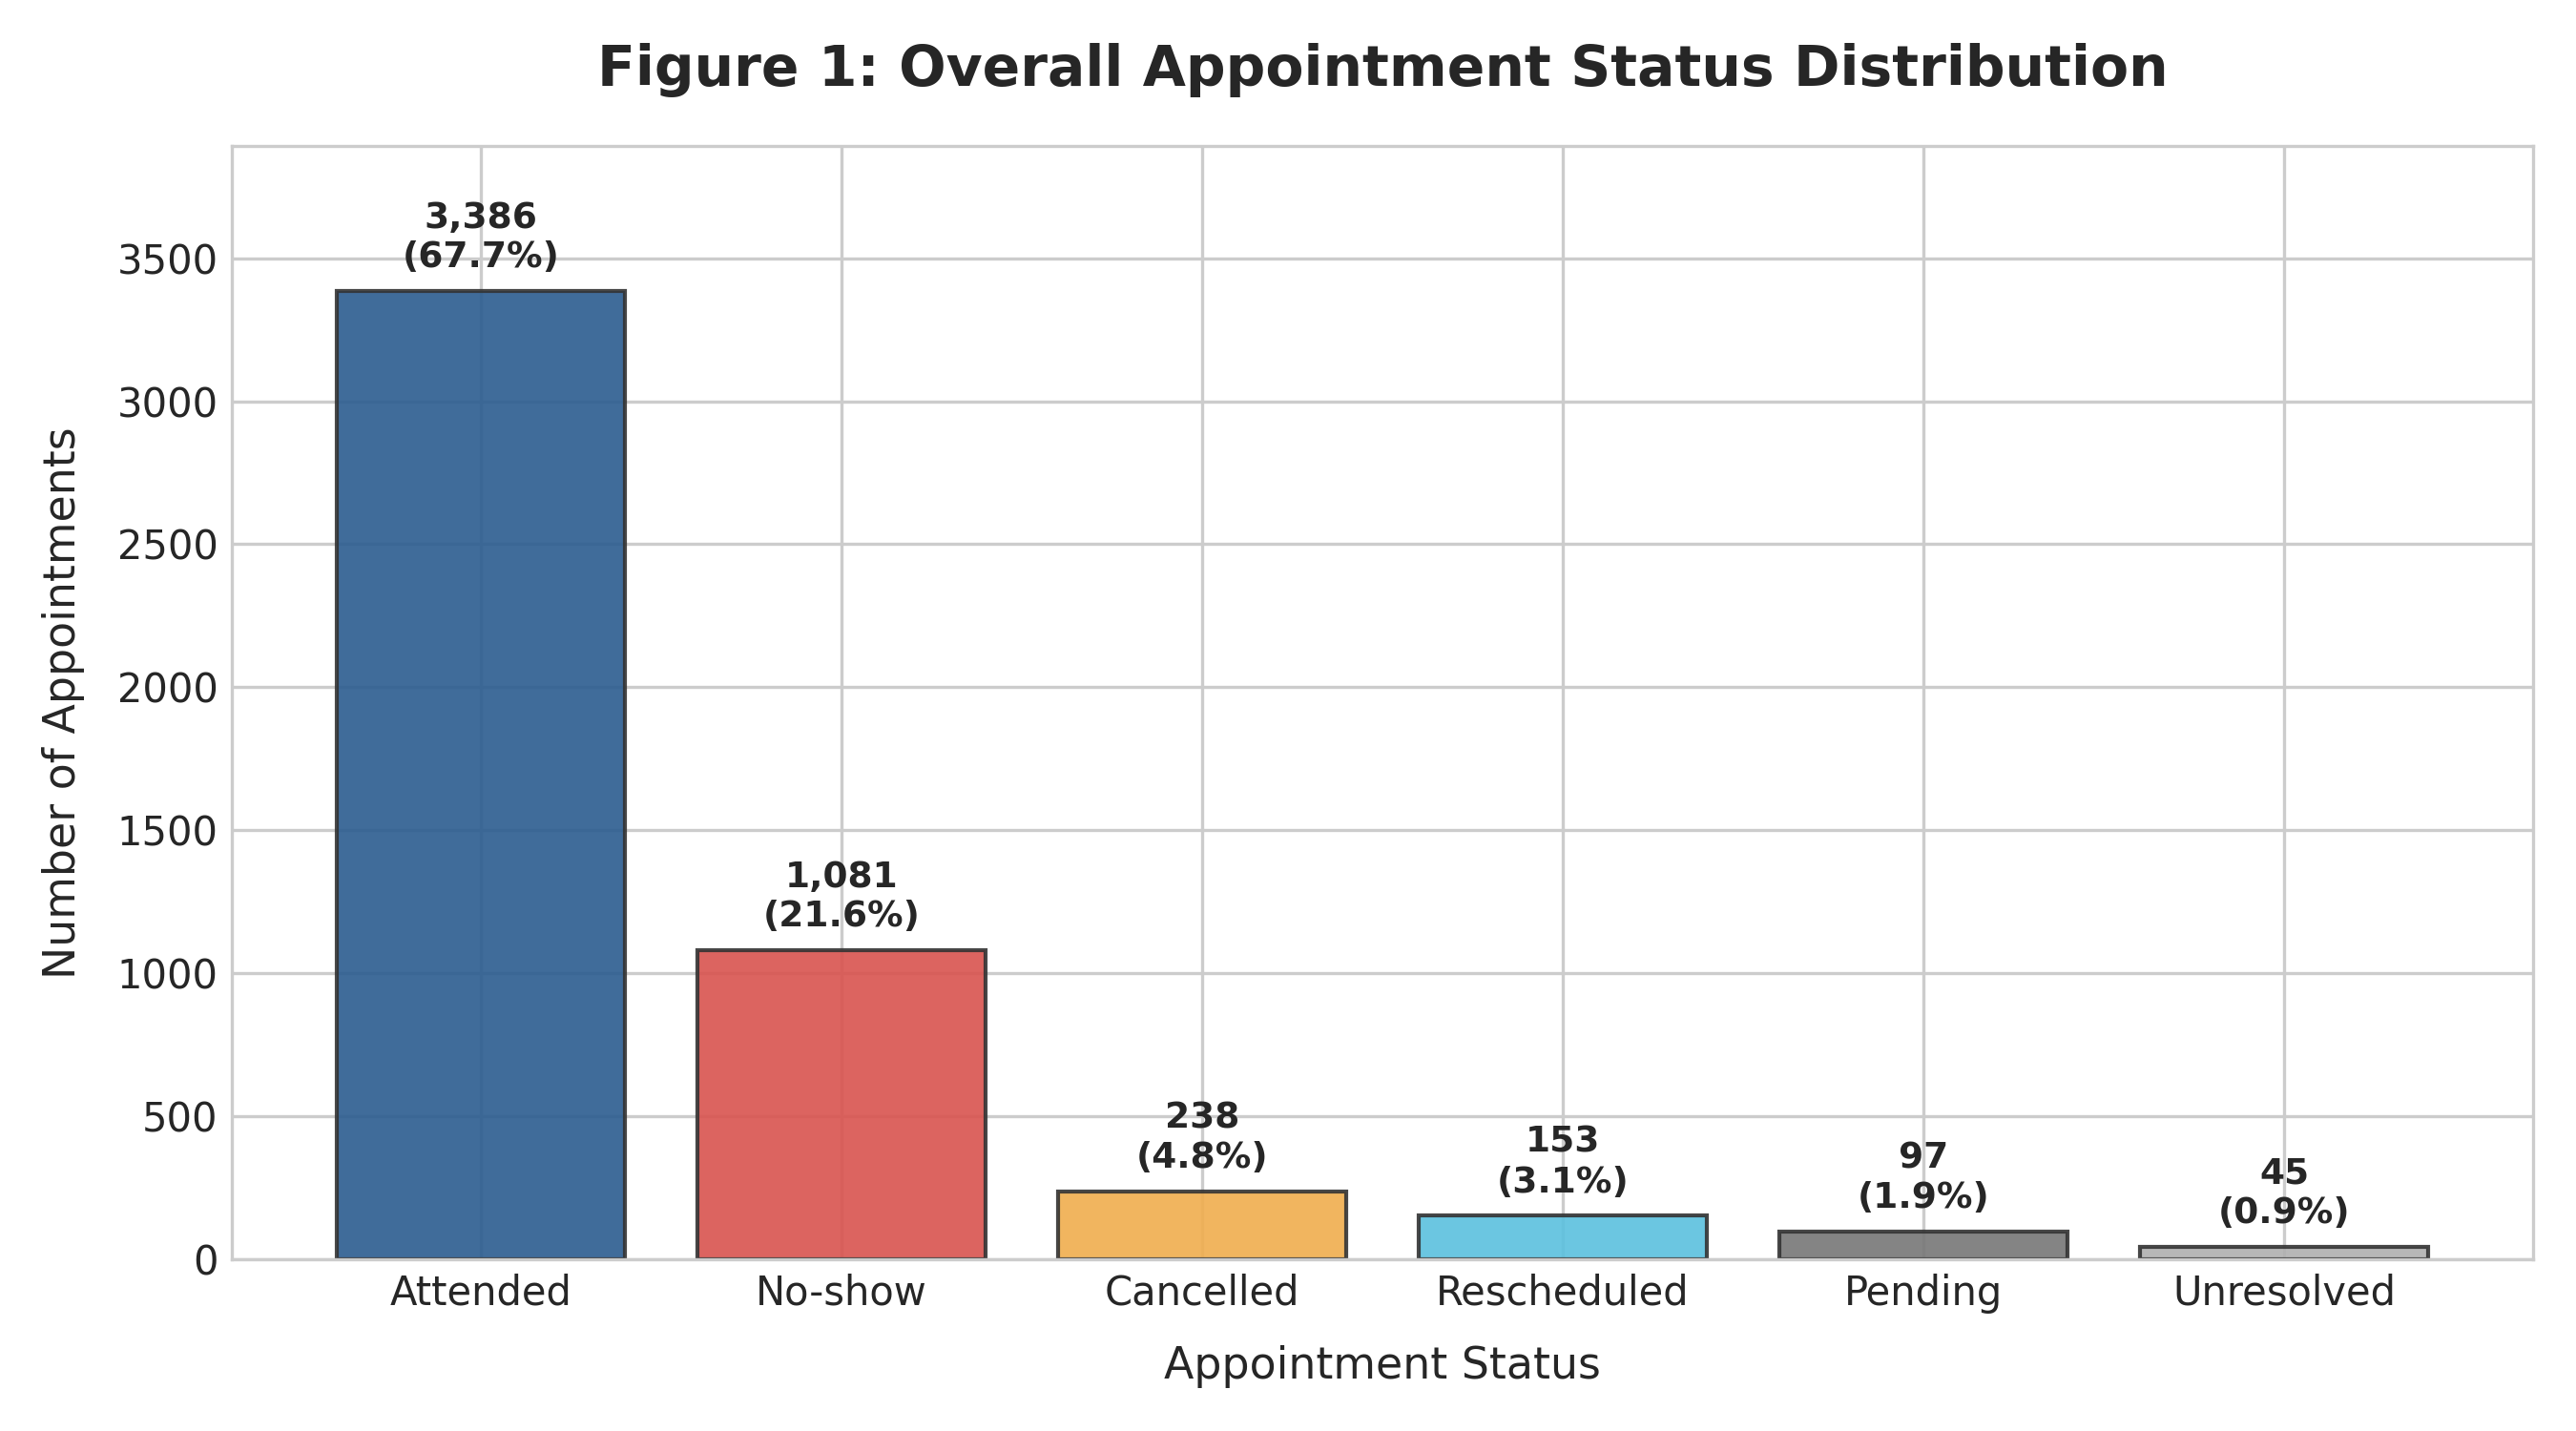

In [7]:
from IPython.display import Image, display
display(Image(filename=os.path.join(fig_dir, 'appointment_status_distribution.png')))

### 3.2 Department-wise No-show Rates

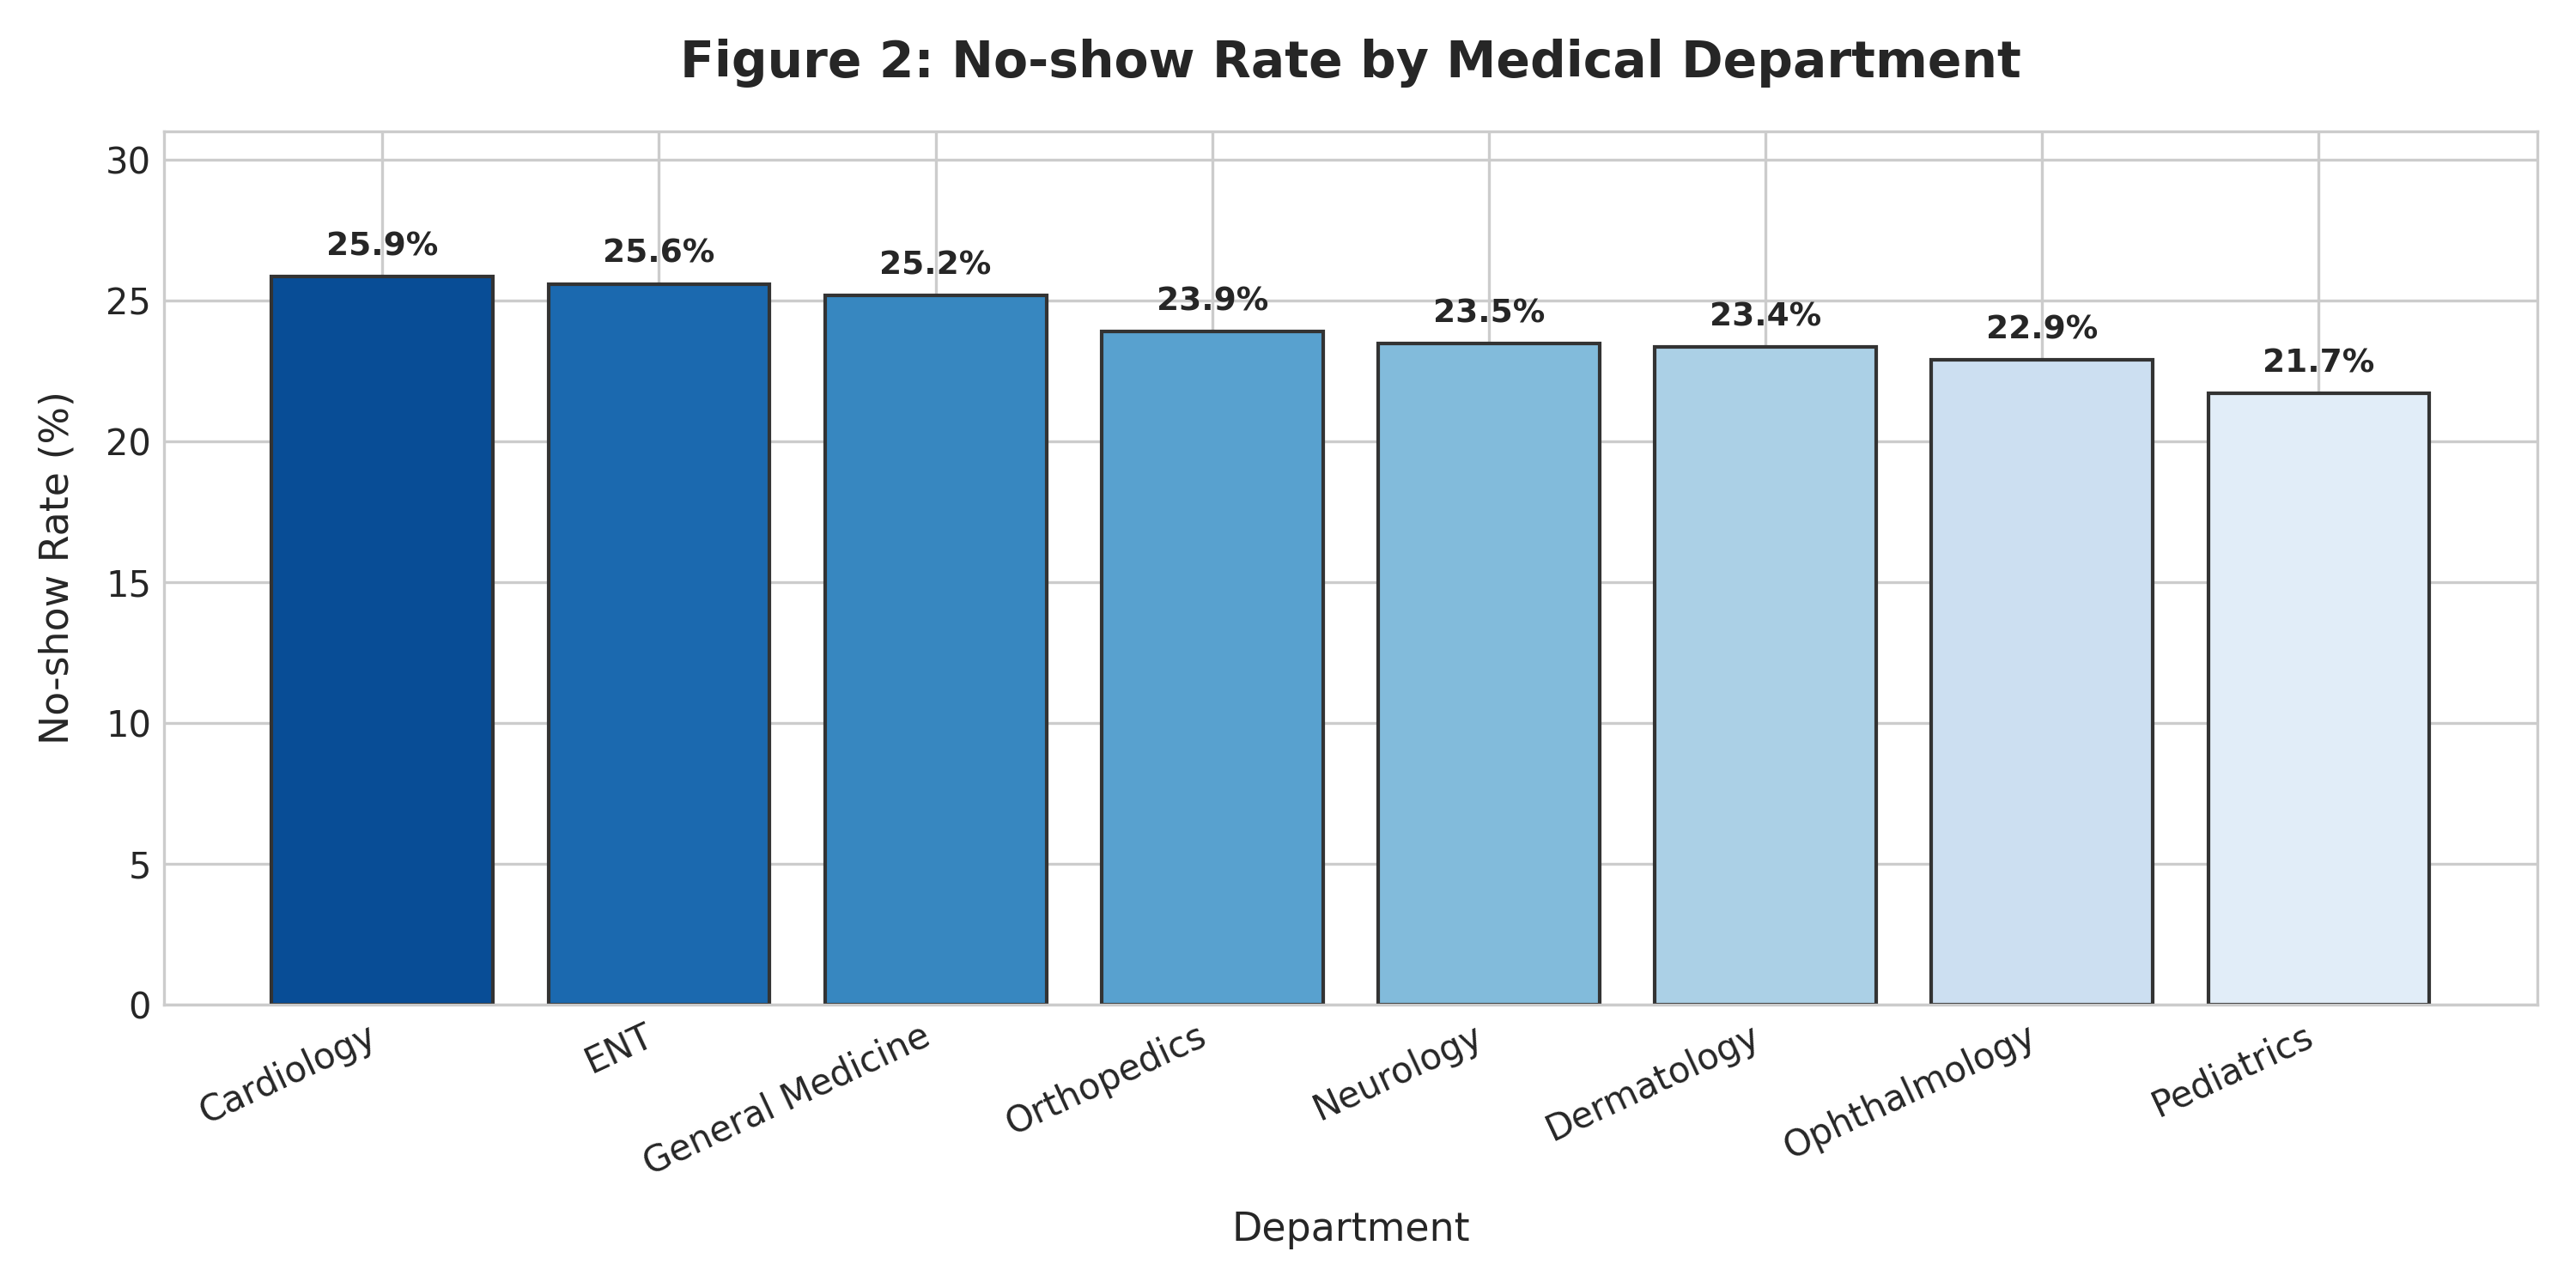

In [8]:
display(Image(filename=os.path.join(fig_dir, 'department_noshow_rate.png')))

### 3.3 Waiting Time vs. No-show Rate

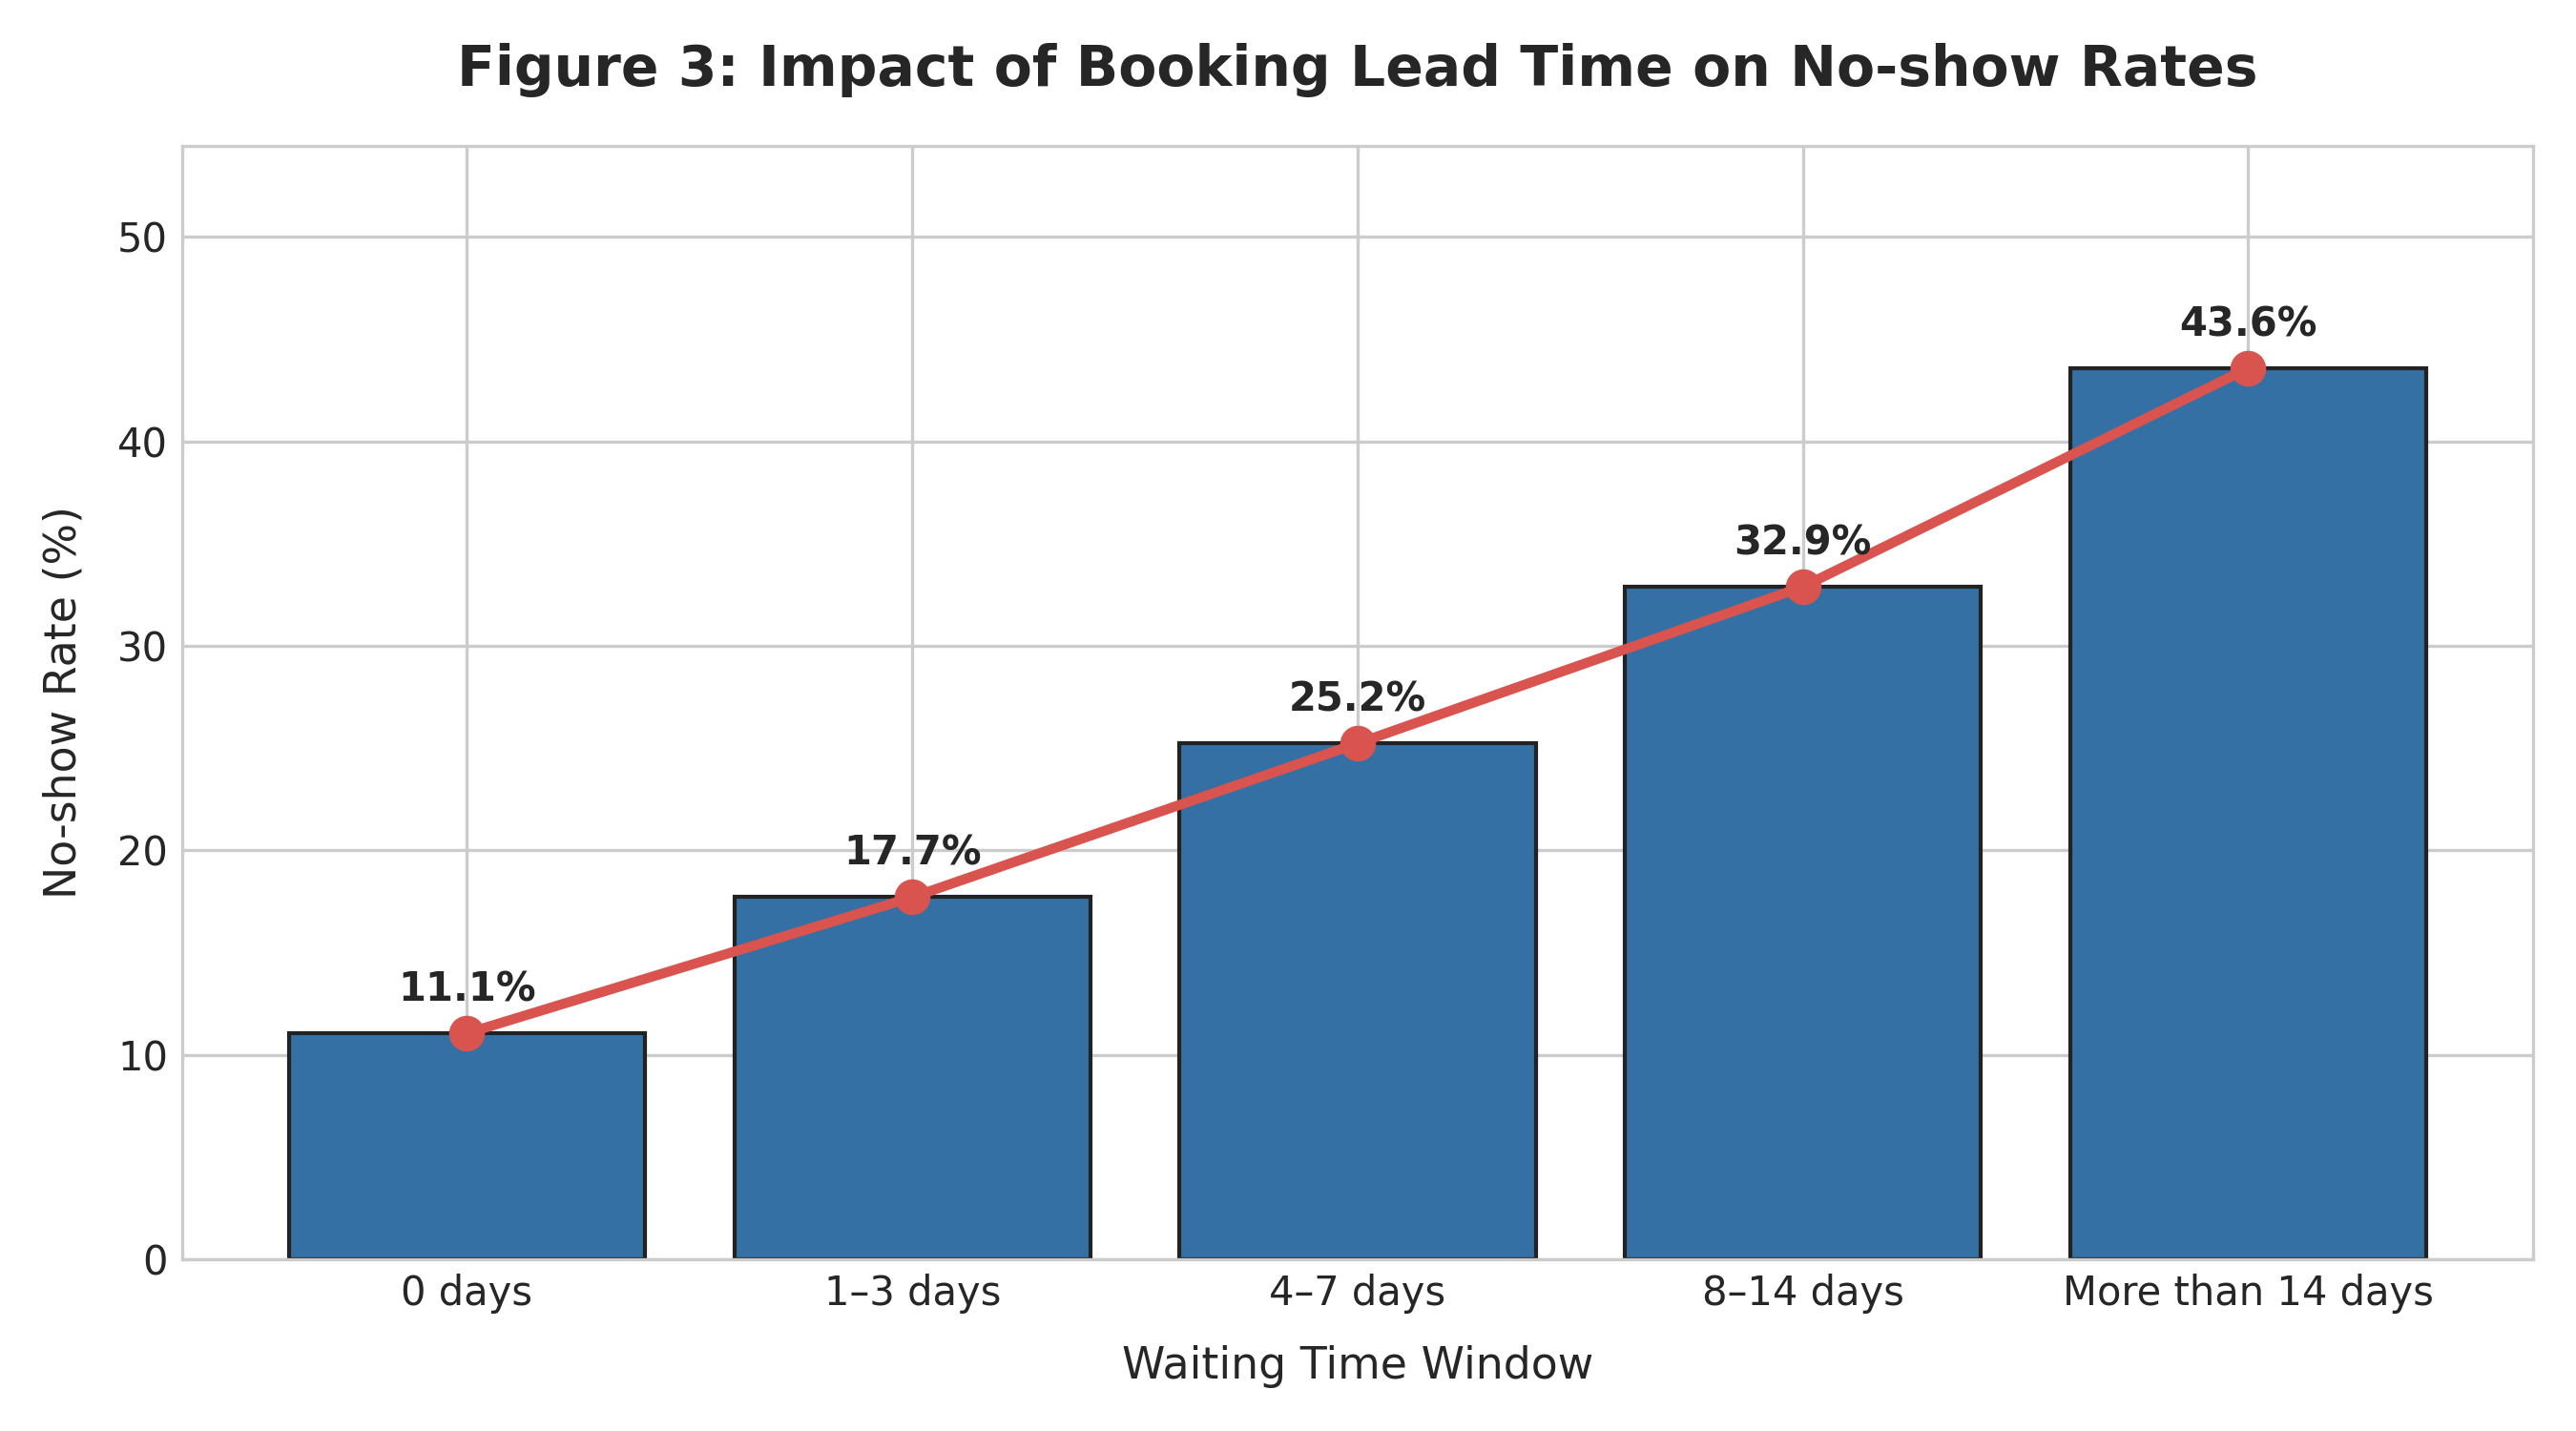

In [9]:
display(Image(filename=os.path.join(fig_dir, 'waiting_time_vs_noshow.png')))

### 3.4 Weekday Attendance Distribution

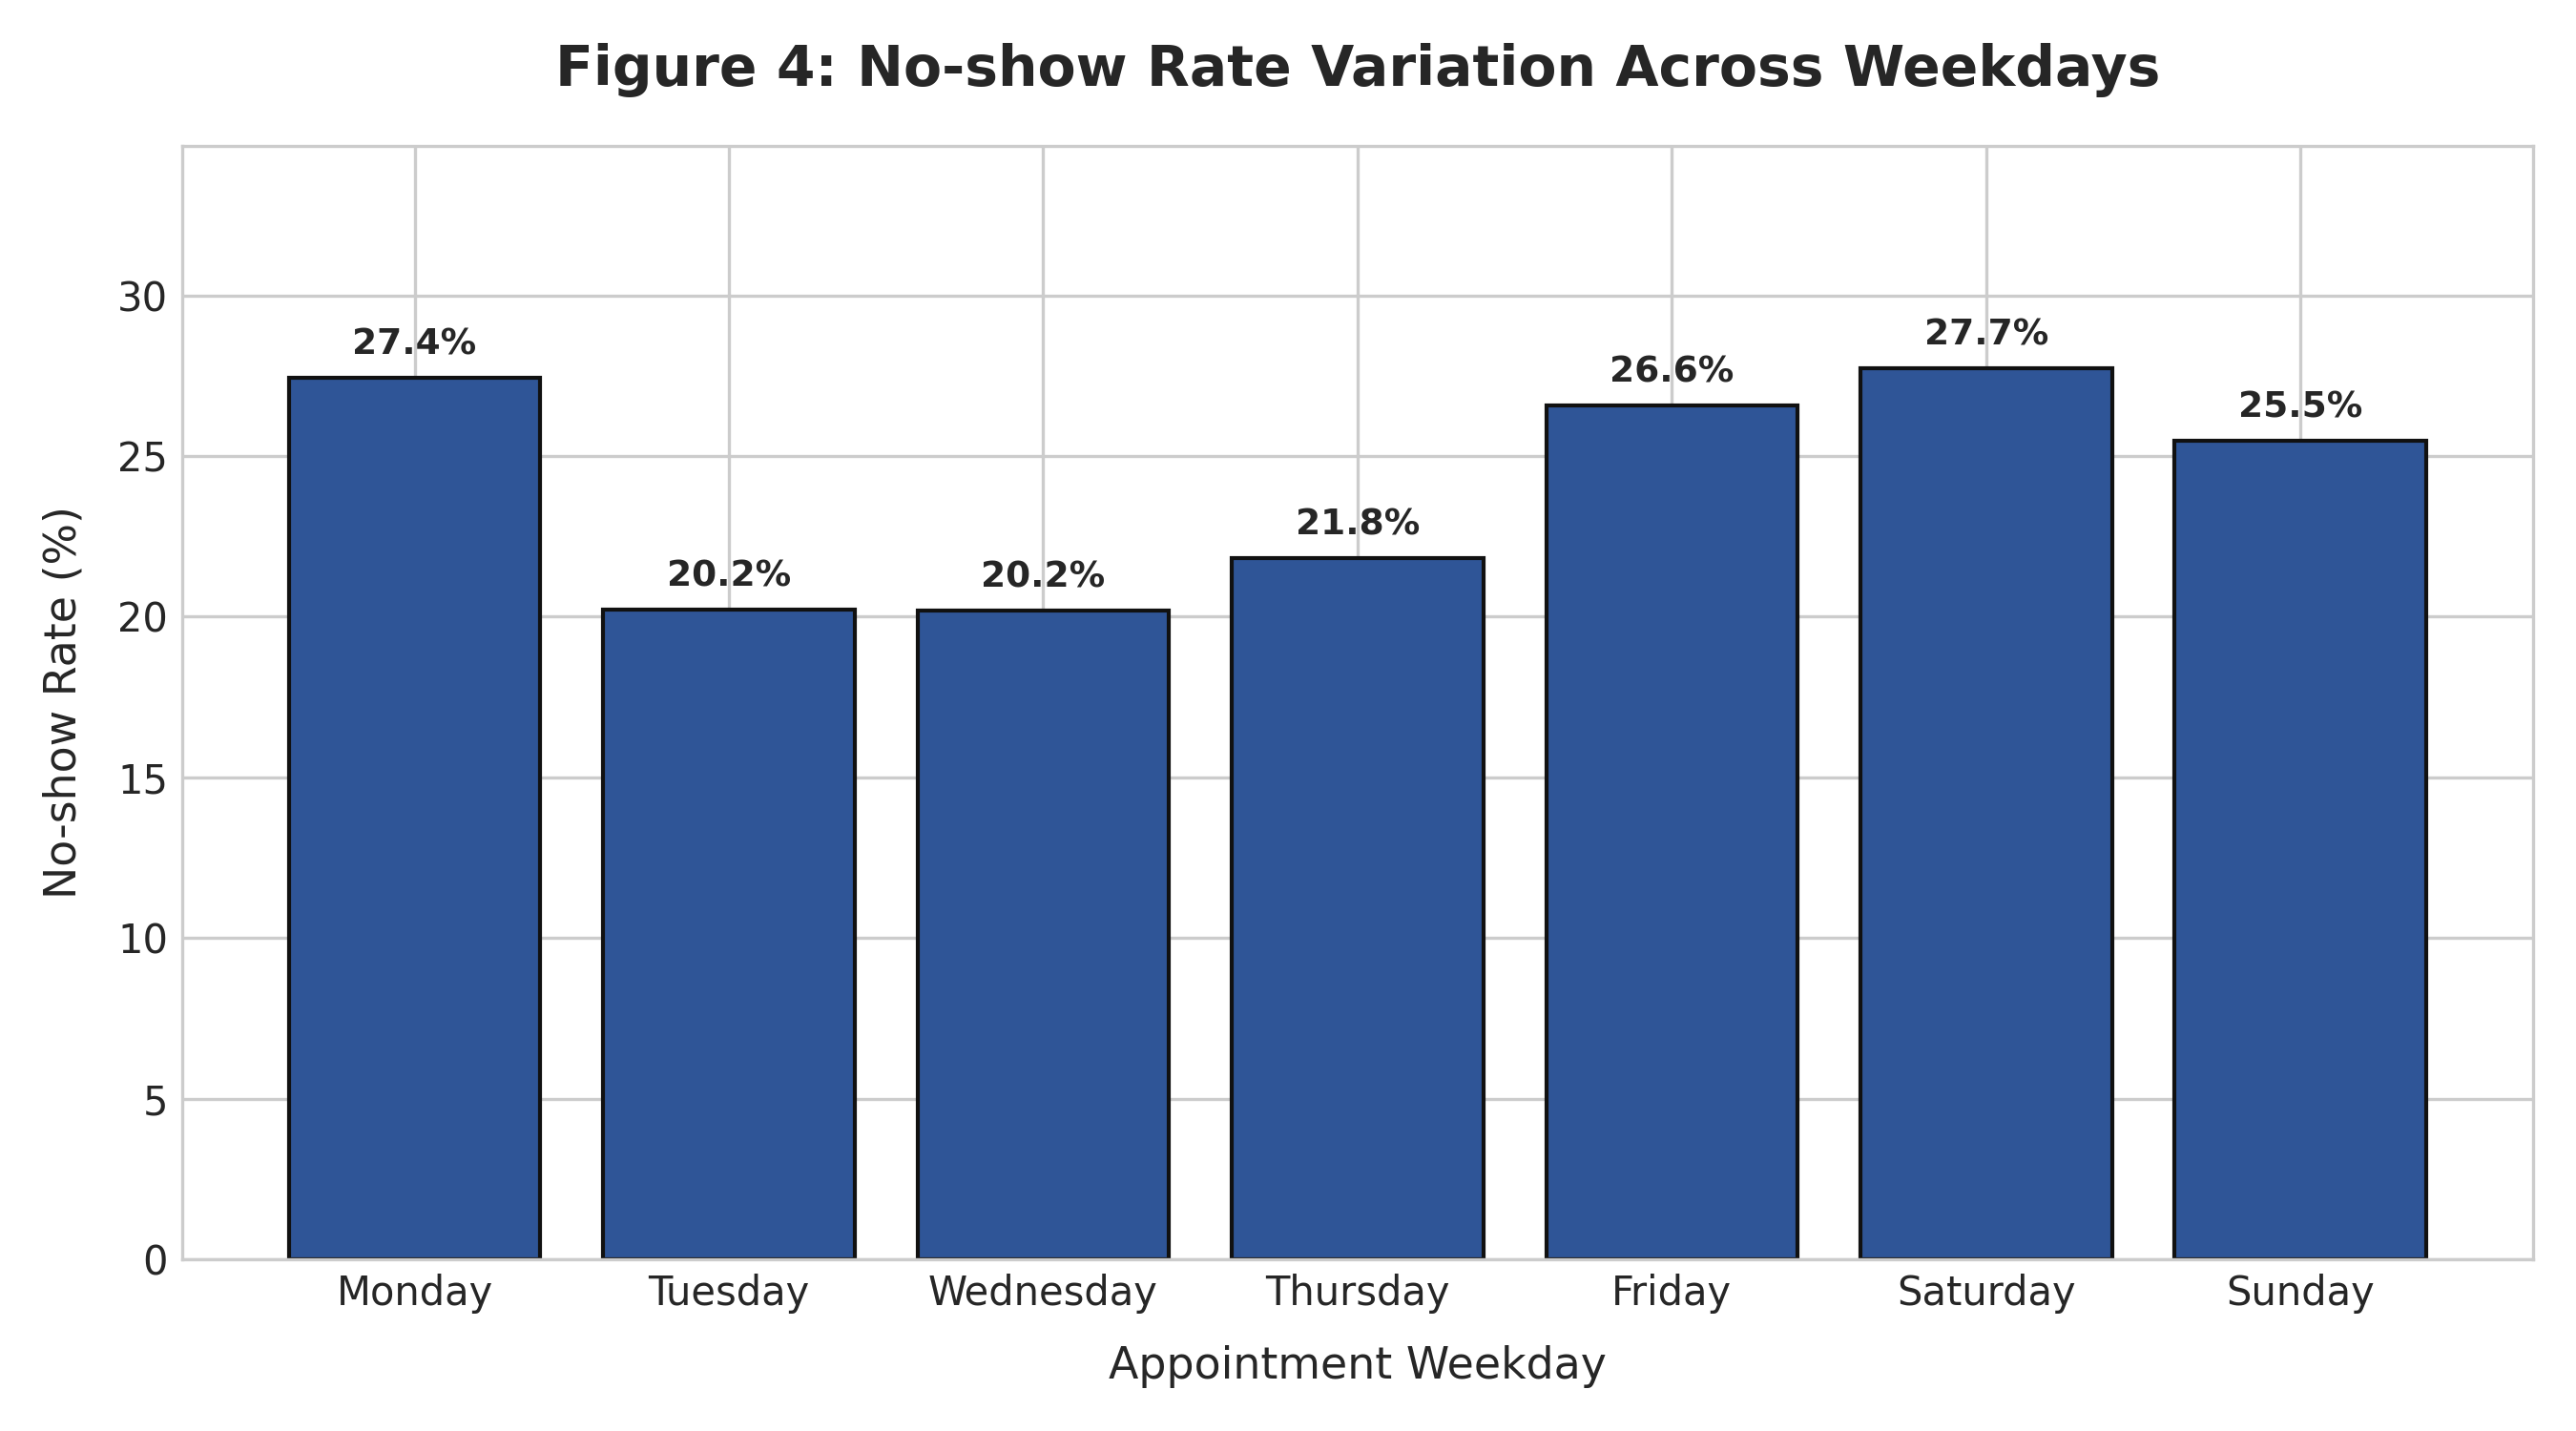

In [10]:
display(Image(filename=os.path.join(fig_dir, 'weekday_noshow_rate.png')))

### 3.5 Reminder Delivery Impact

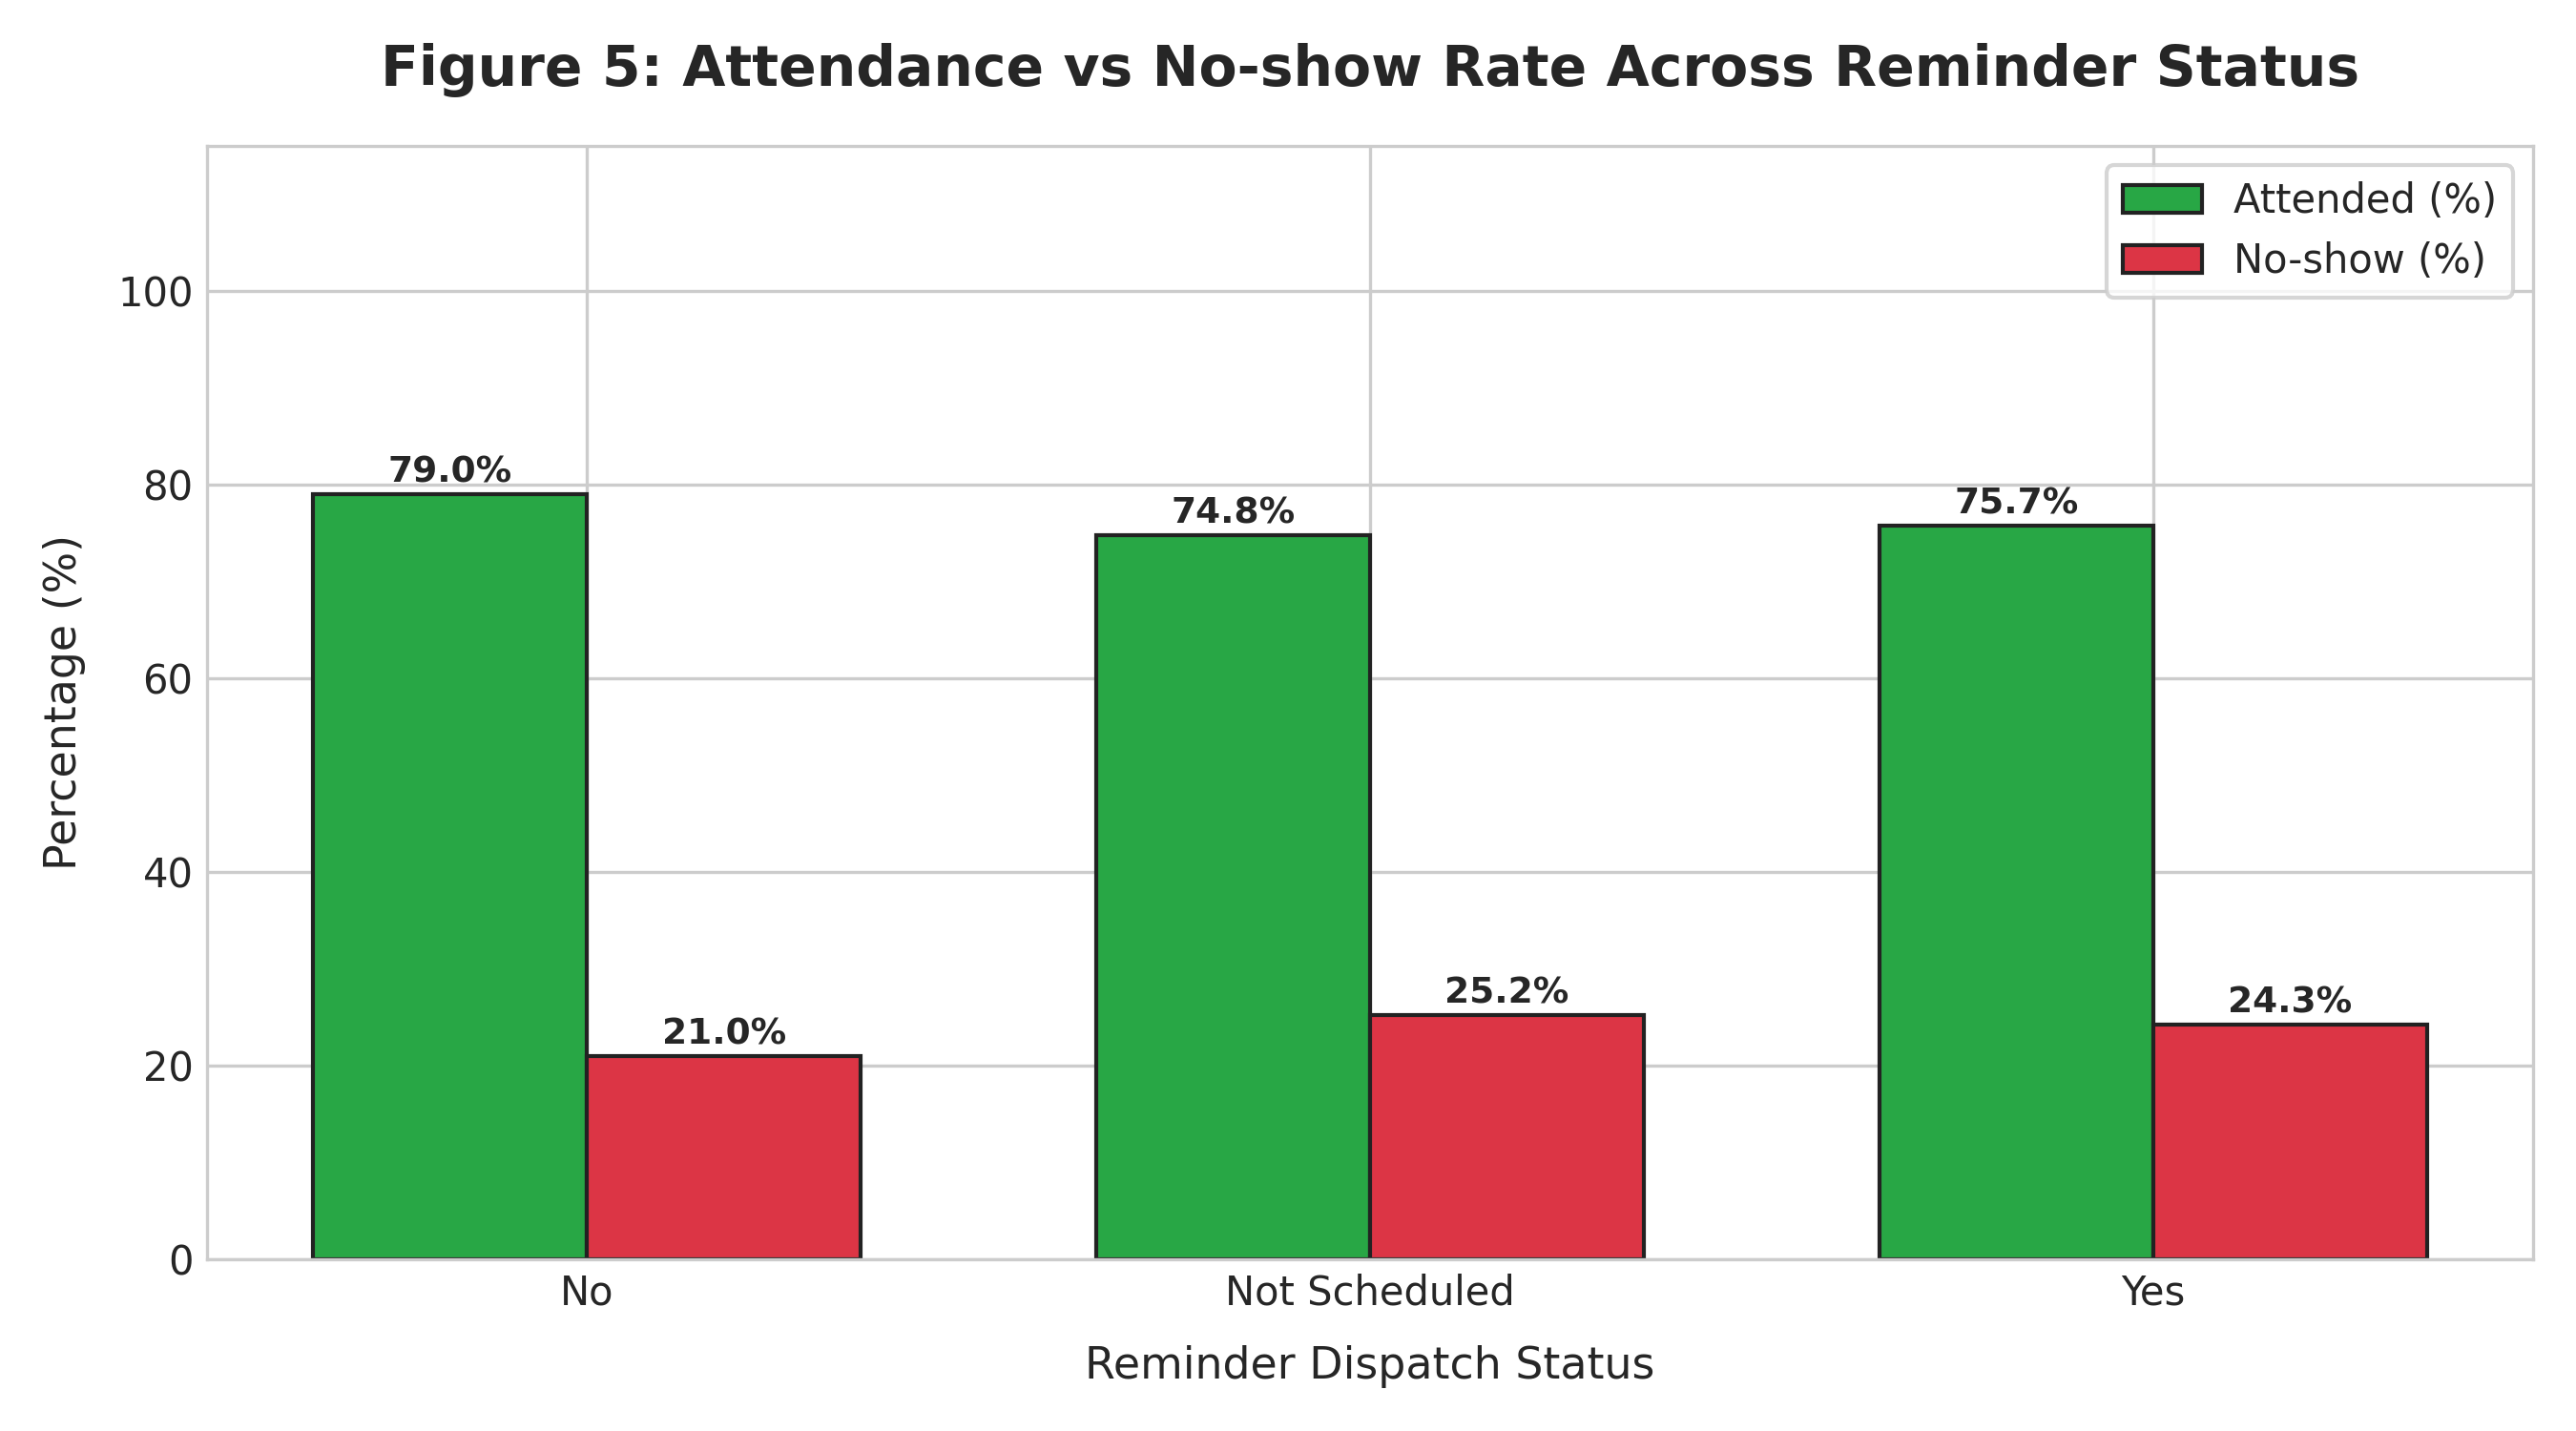

In [11]:
display(Image(filename=os.path.join(fig_dir, 'reminder_status_vs_attendance.png')))

### 3.6 Prior Missed Visits vs. Current No-show Rate

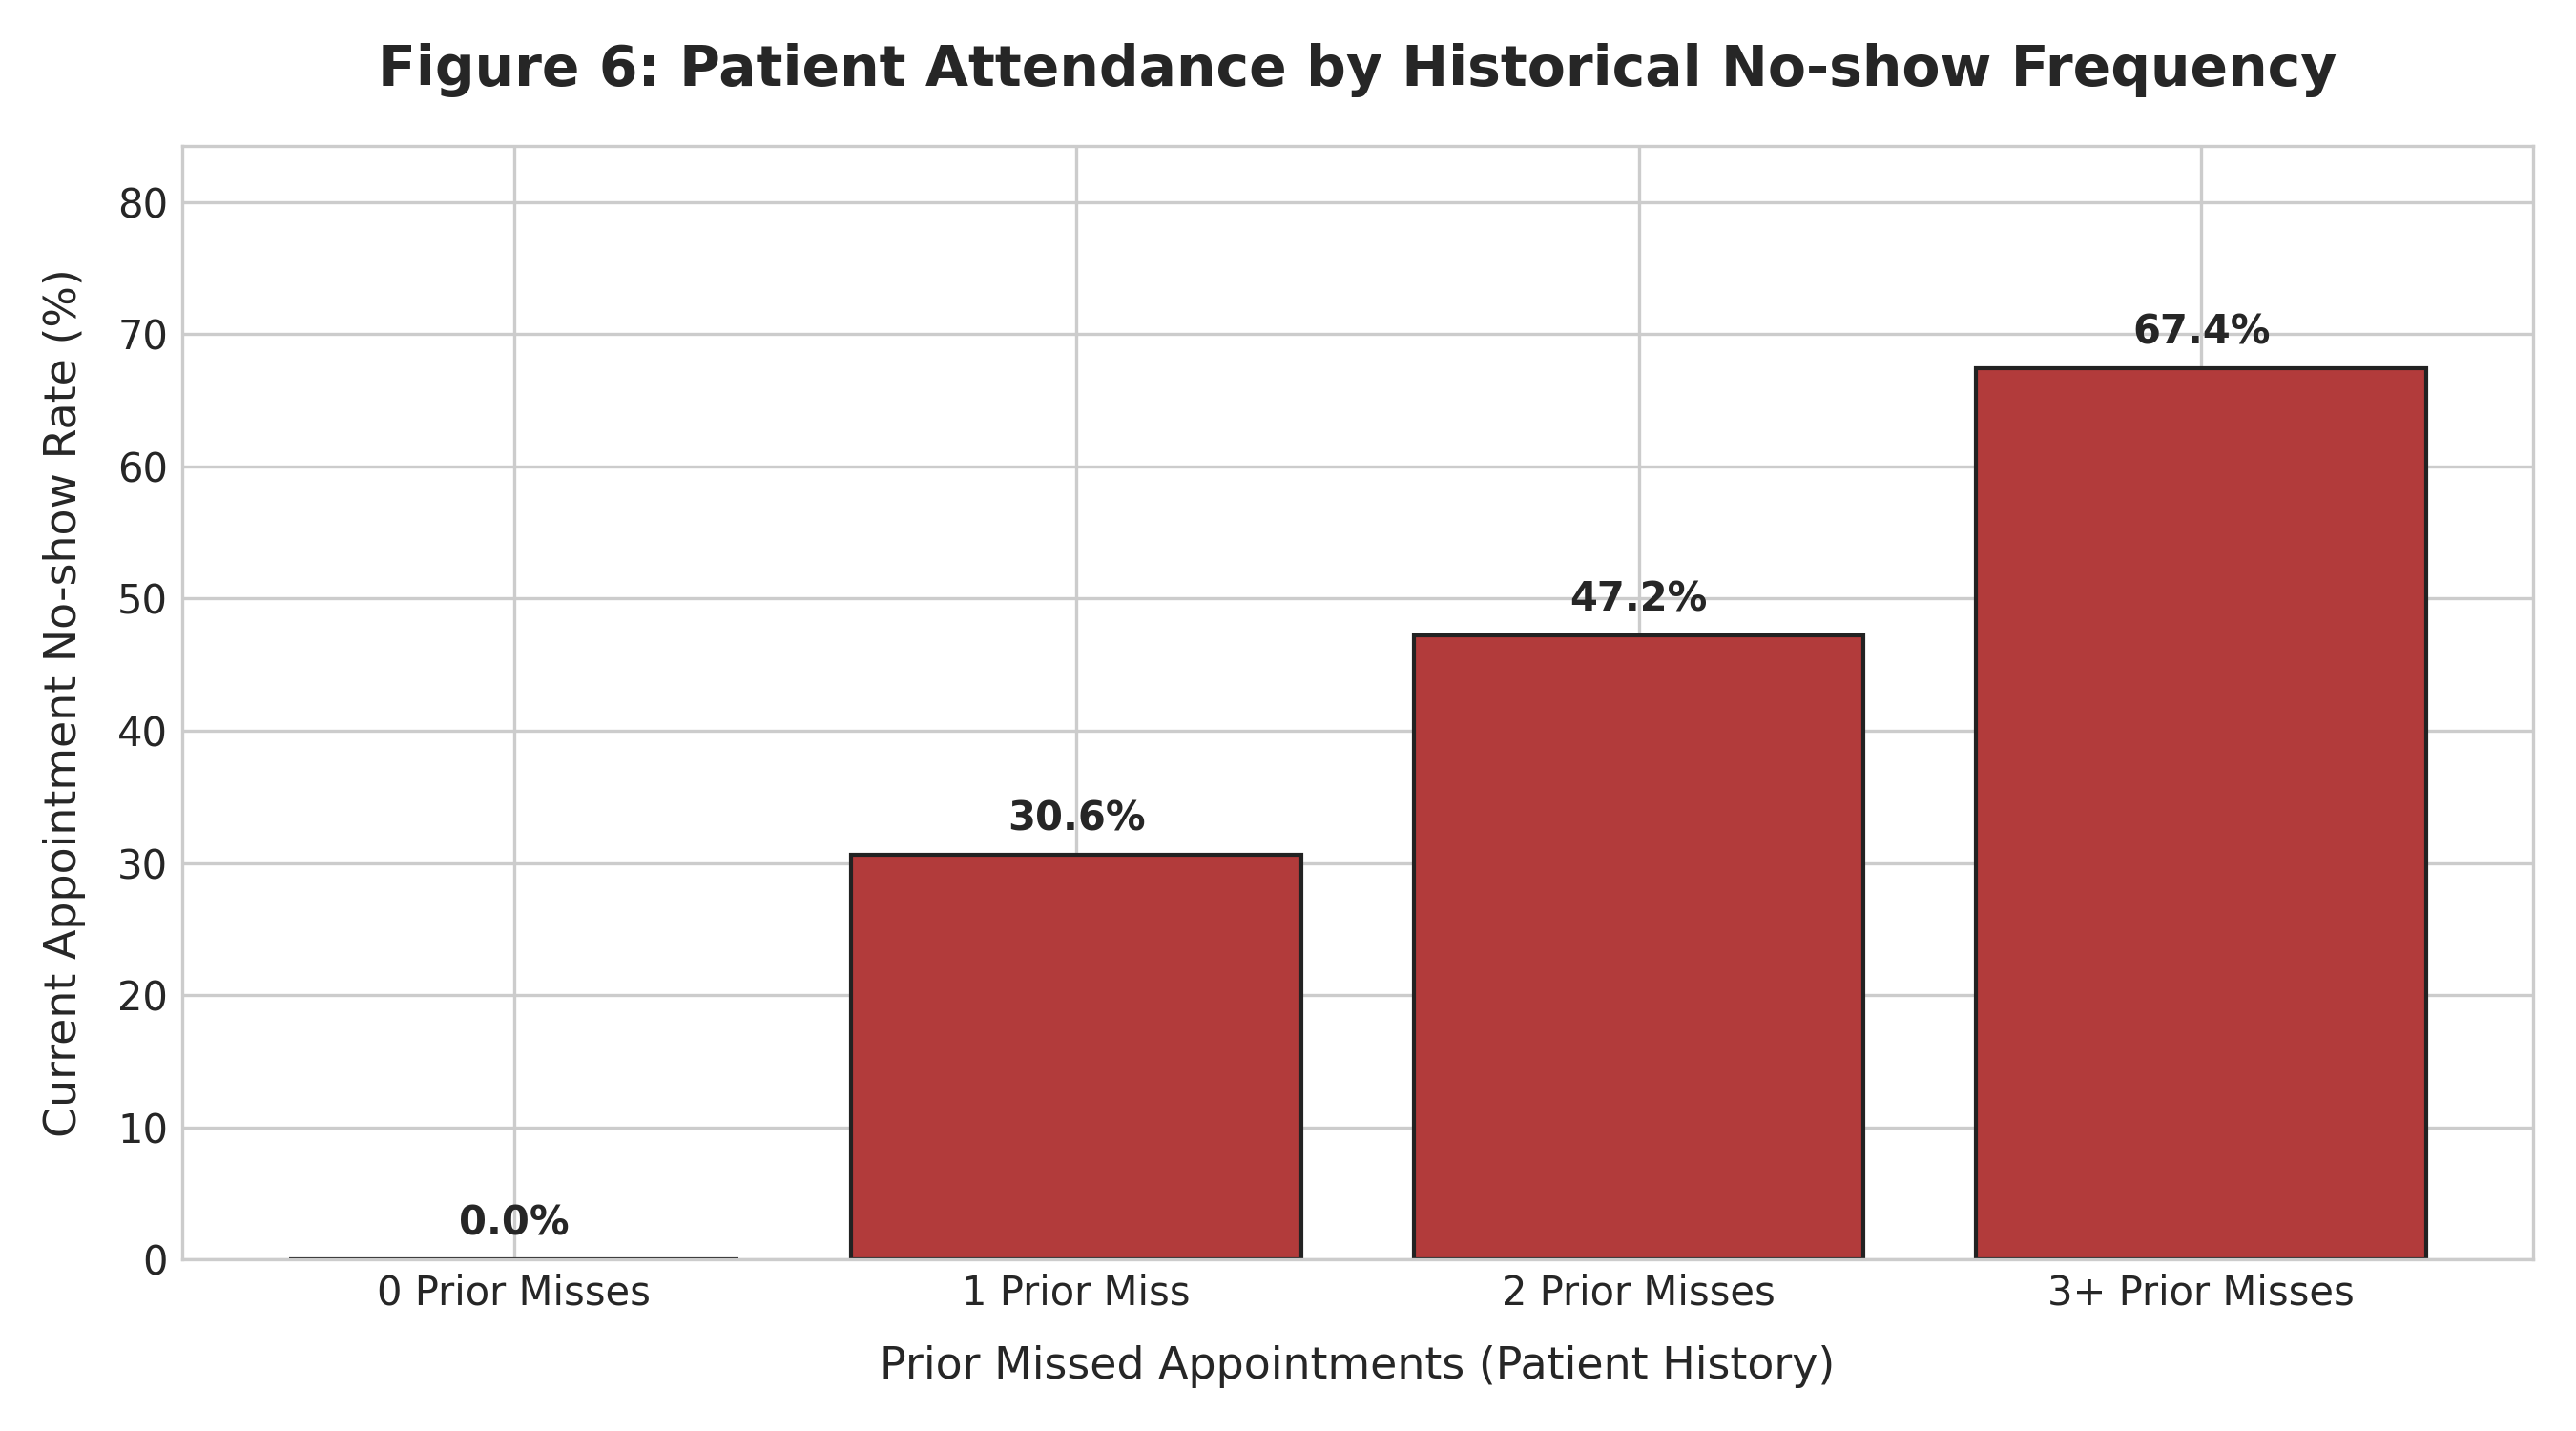

In [12]:
display(Image(filename=os.path.join(fig_dir, 'previous_noshow_vs_current.png')))

### 3.7 Age Cohort Attendance Trends

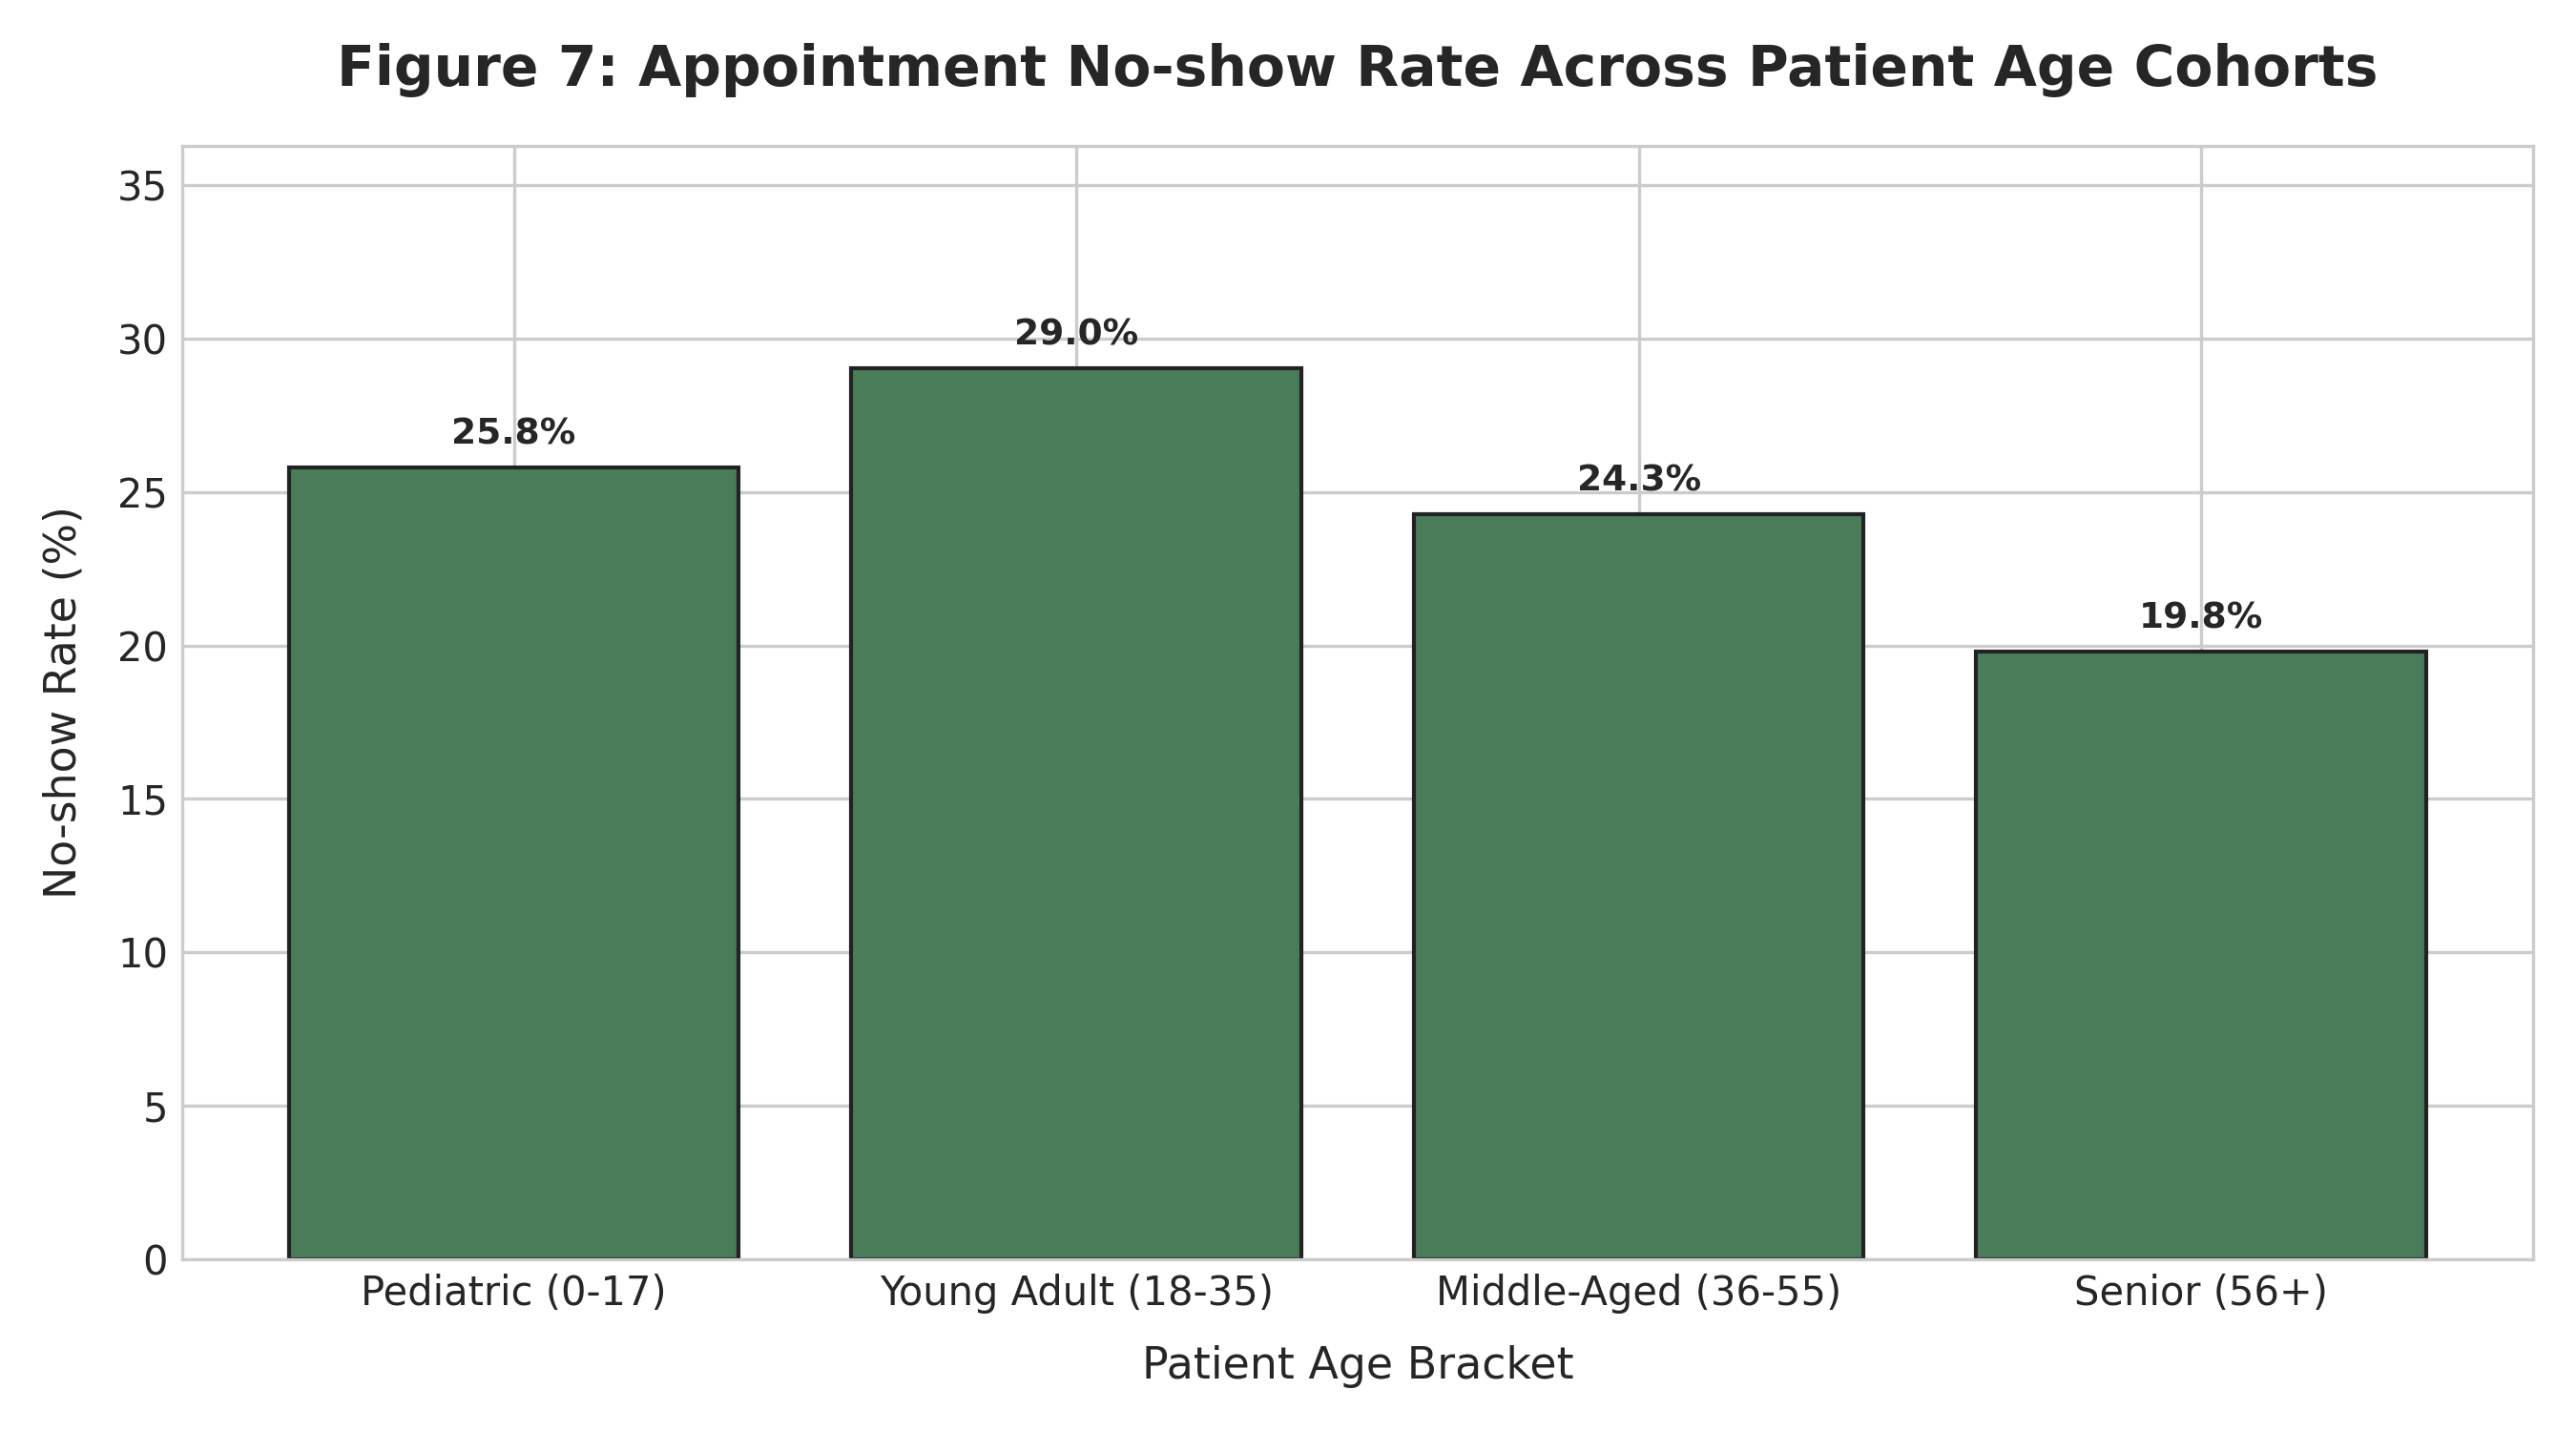

In [13]:
display(Image(filename=os.path.join(fig_dir, 'age_group_attendance.png')))

### 3.8 Medical Specialty Load Comparison

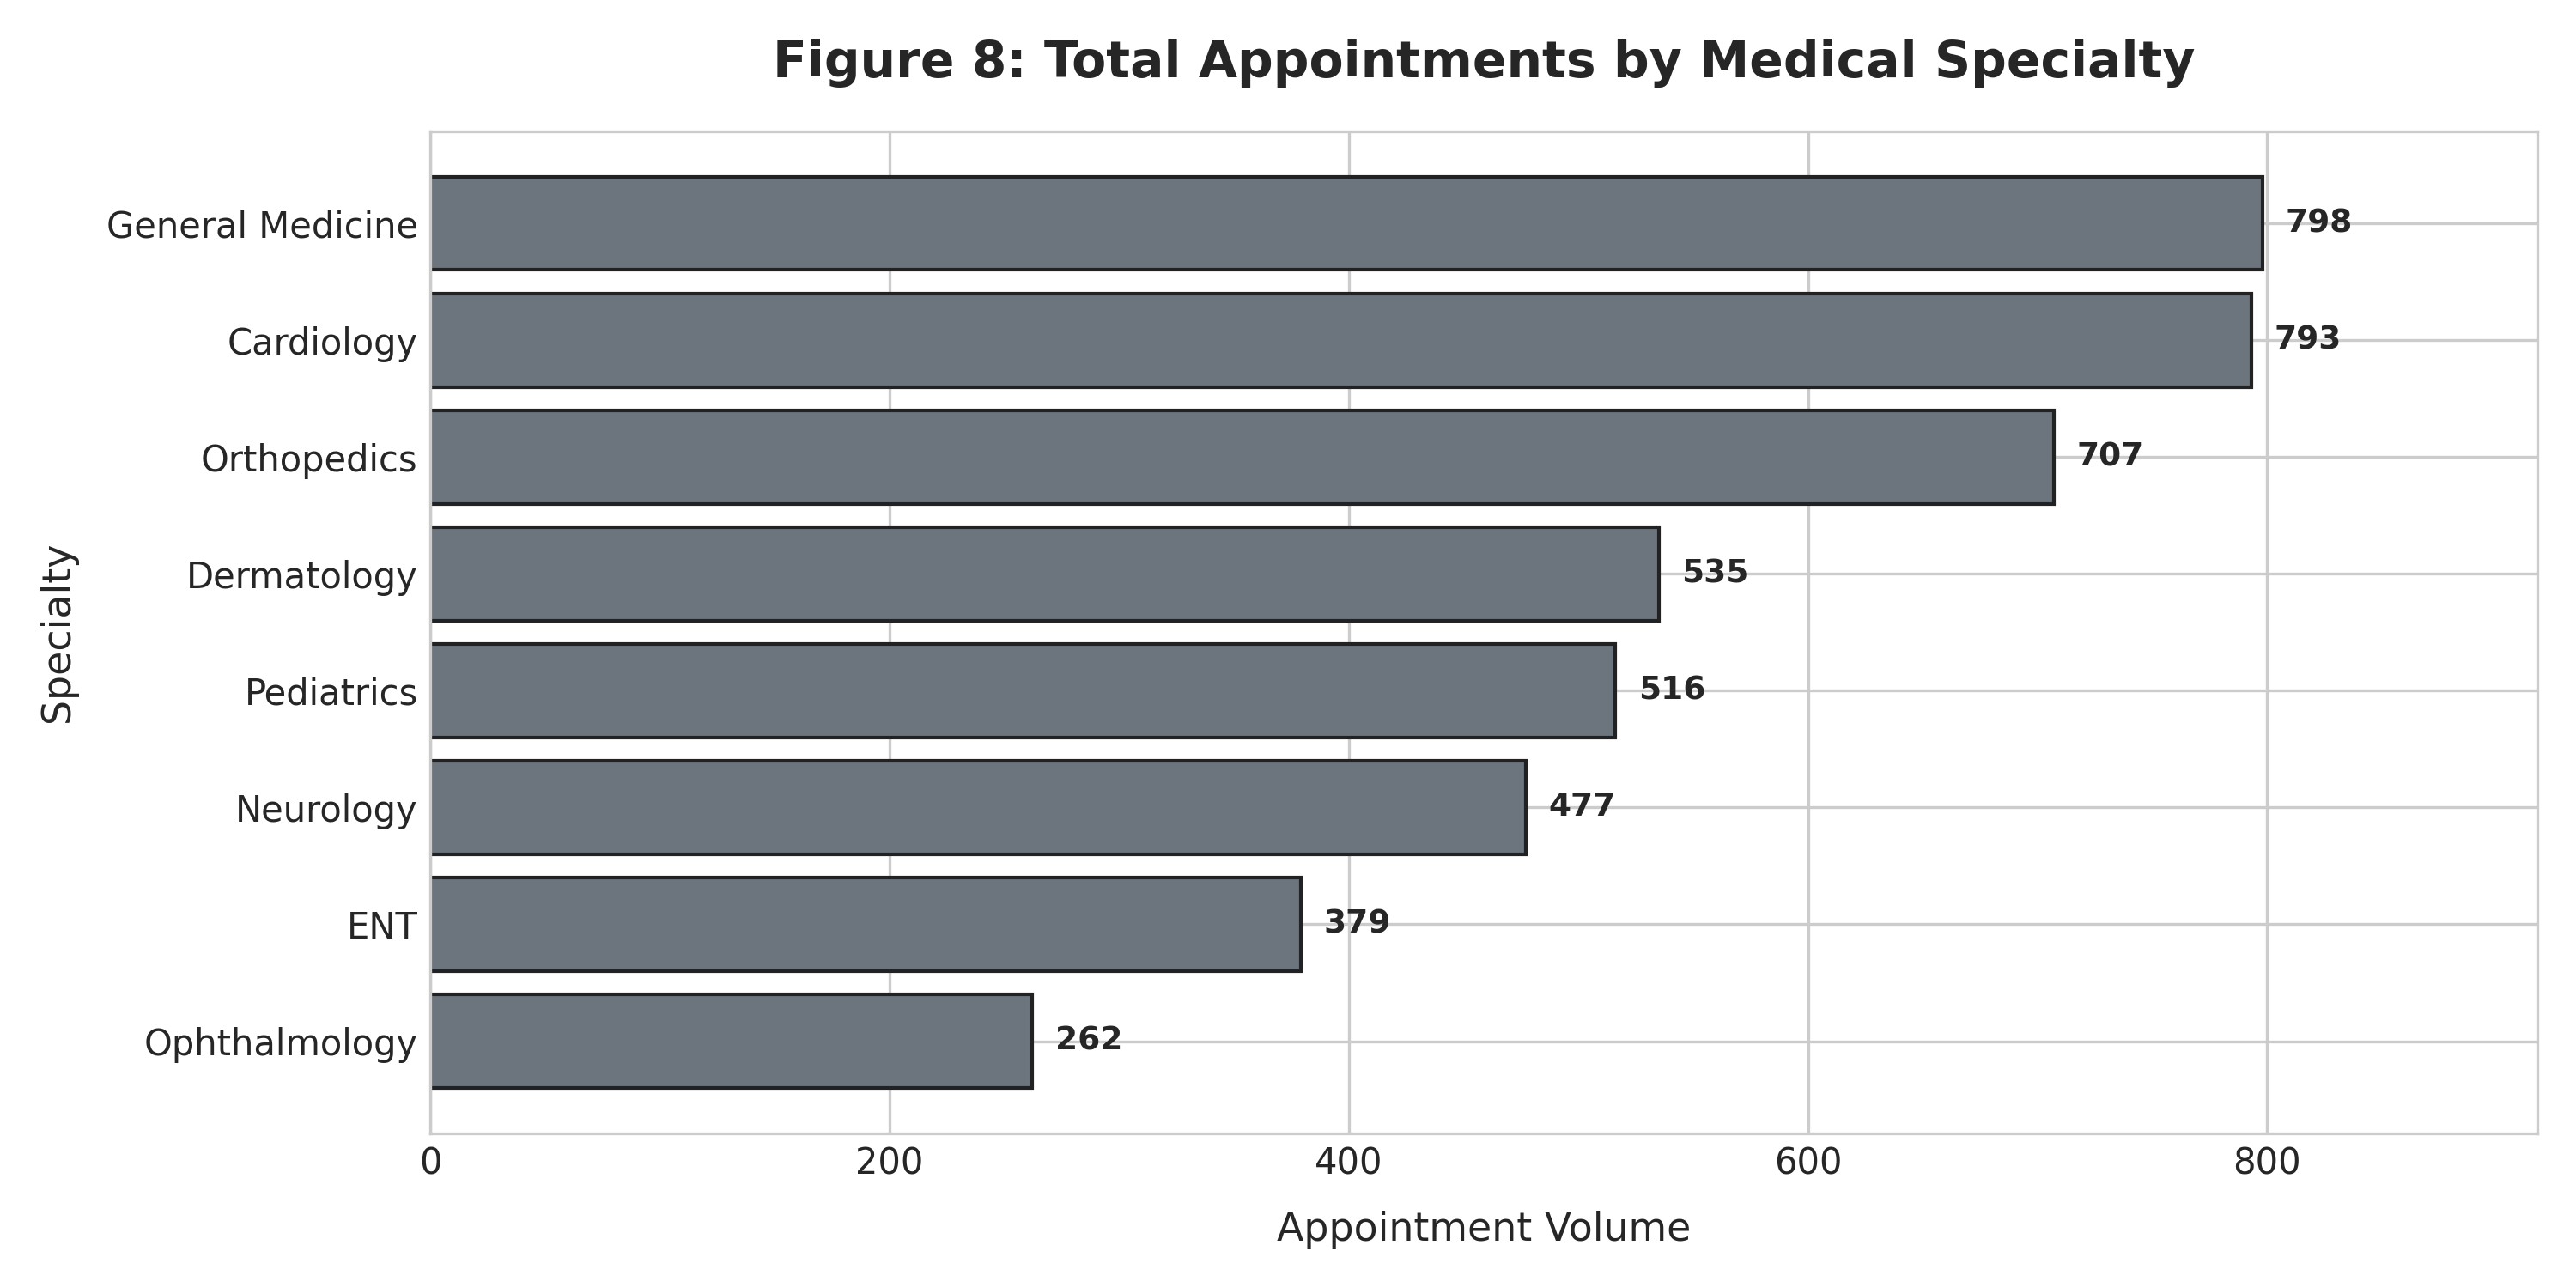

In [14]:
display(Image(filename=os.path.join(fig_dir, 'doctor_specialty_comparison.png')))

### 3.9 Monthly and Seasonal Trends

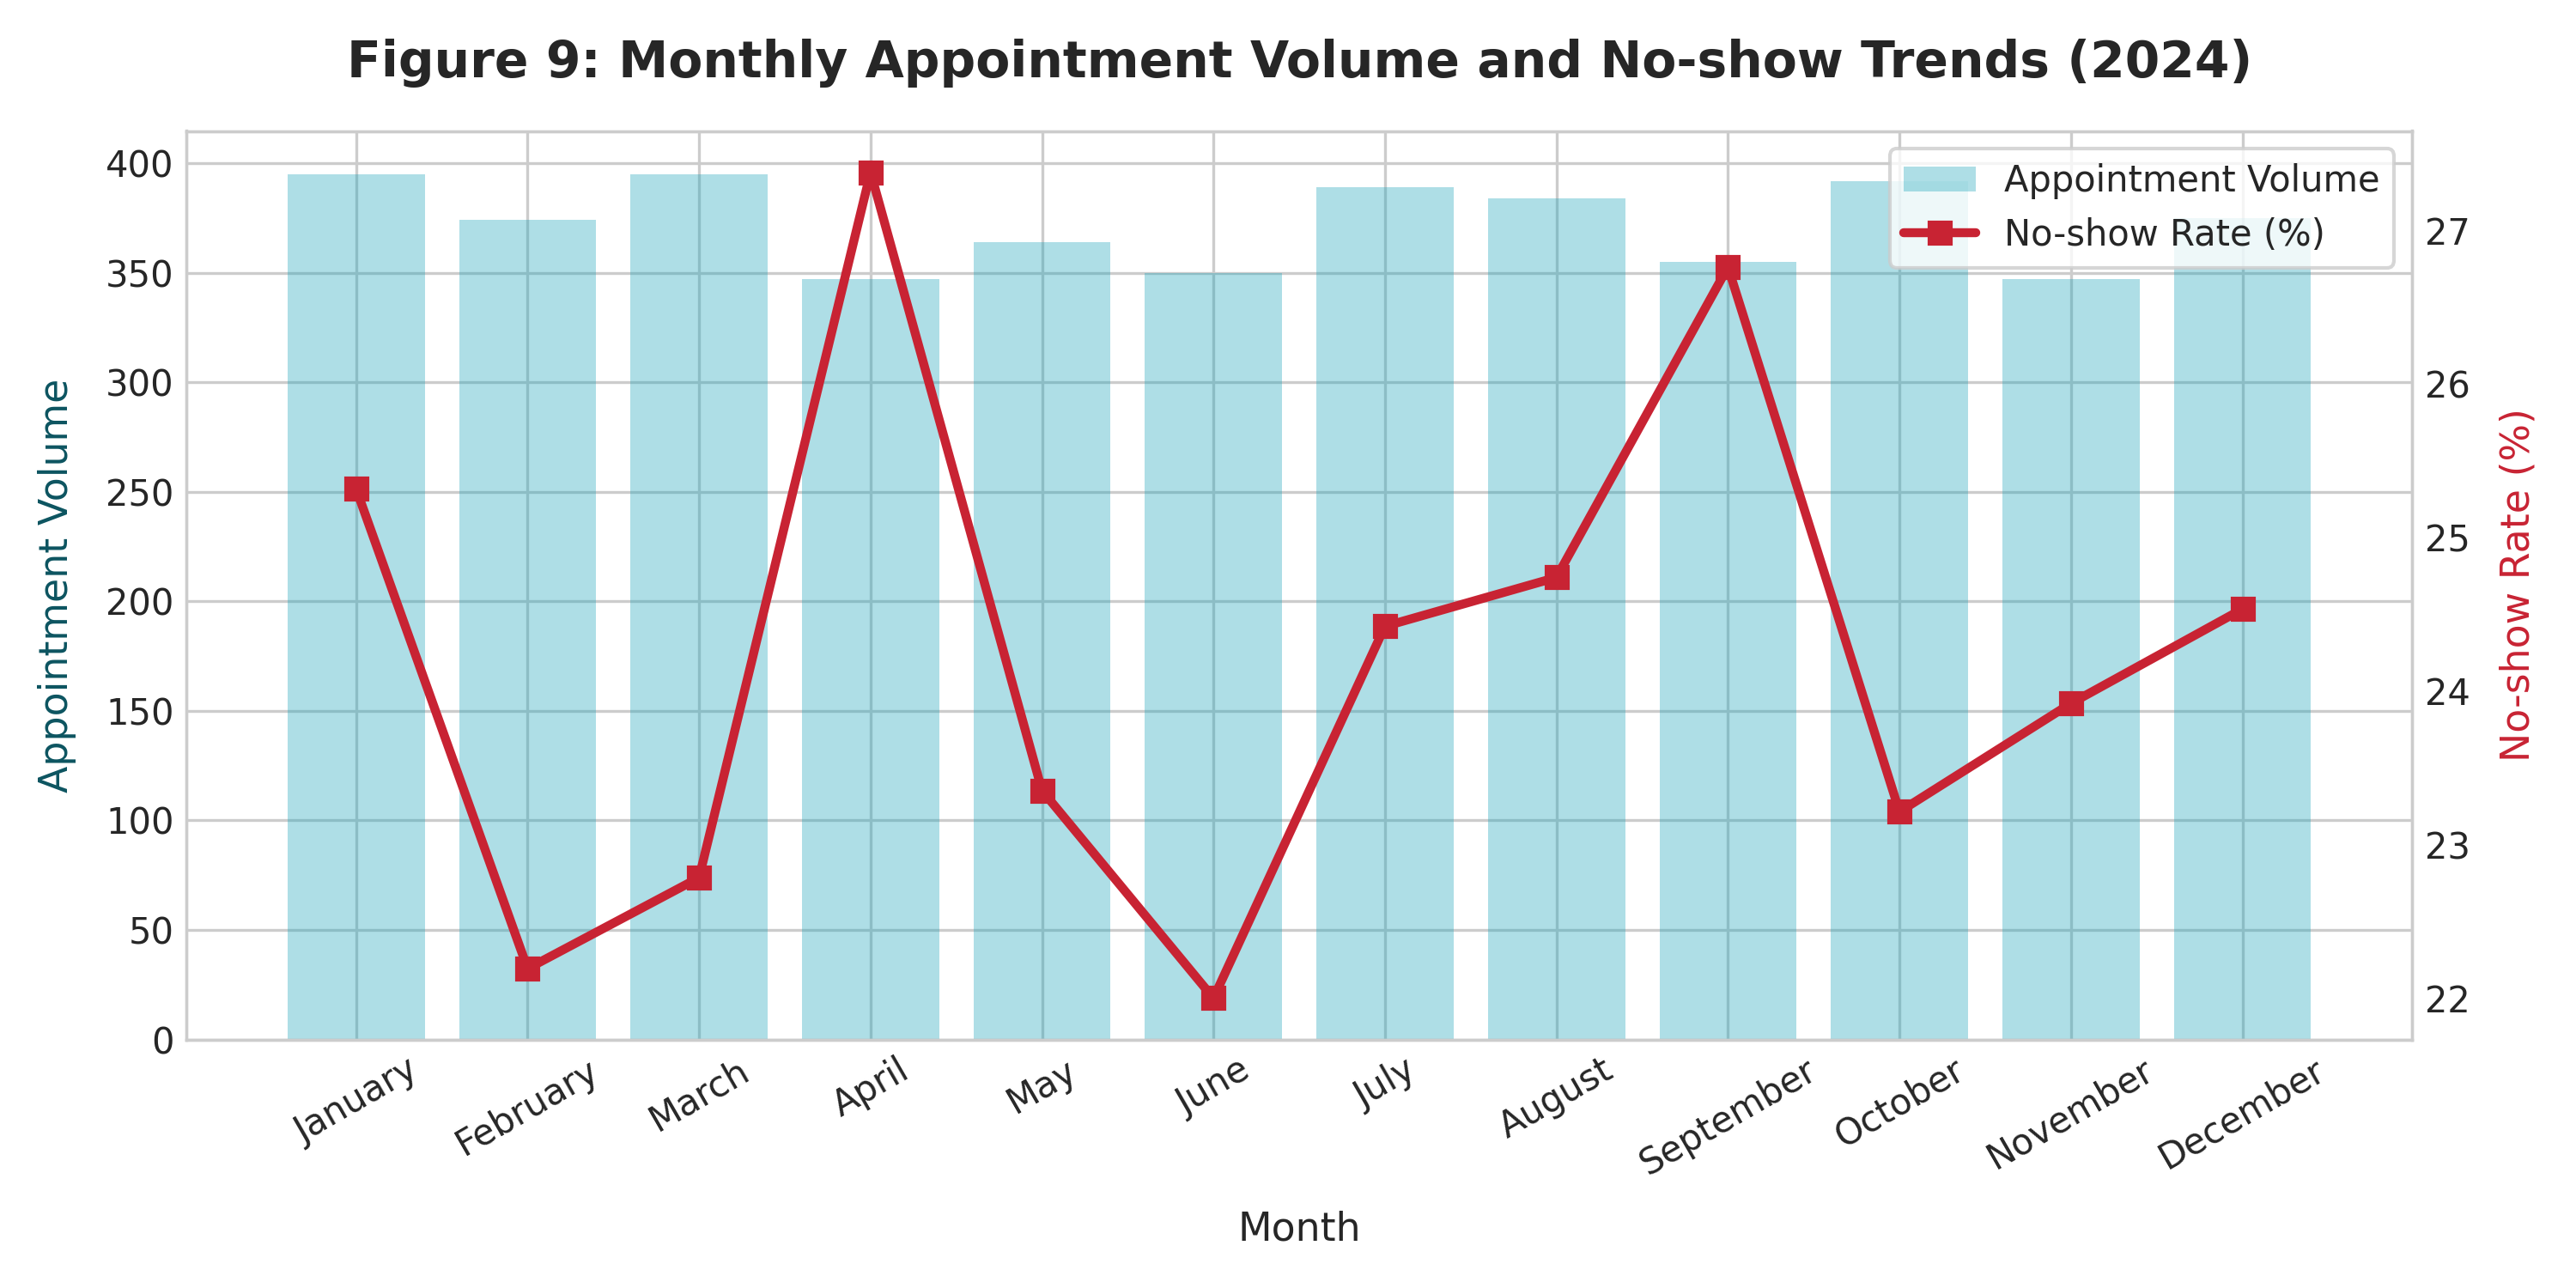

In [15]:
display(Image(filename=os.path.join(fig_dir, 'monthly_seasonal_trends.png')))

## Summary of Business Insights from Round 1
- **Lead Time:** Appointments booked >14 days in advance show ~33% no-show rates vs ~12% for same-day bookings.
- **Patient Recidivism:** Patients with 2 or more historical no-shows have >45% repeat no-show risk.
- **Departments:** General Medicine and Orthopedics have the highest missed appointment volumes.
- **Reminders:** Confirmed responses show strong positive correlation with attendance (>85%).